# Notebook 5: Grad-CAM attention on the weapon, same architecture in every scenario

Answers the reviewer question: *did attention on the weapon drop in E3 because of multi-weapon clutter, or because Grad-CAM behaves differently on a vision transformer?*

It computes the share of Grad-CAM attention on the weapon mask for **ConvNeXt-Tiny and ViT-S/16 in all three scenarios** (E1 all, E2 single, E3 multi), each with the pipelines K1 (background kept), F (final recipe) and R1 (background removed), using the saved fold-0 models of Notebook 2. Every number comes from the same code, so the rows are directly comparable. No training is done.

## Inputs (Add Input -> Your Work)
| Input | Used for |
|---|---|
| Stage 0 output (`stage0/metadata/manifest.csv`) | test images and labels |
| Notebook 1 output (`bg_removed/mask_manifest.csv`) | weapon masks and background-removed images |
| Notebook 2 output, final version (`results/all`, `results/single`, `results/multi`) | fold-0 weights and pipeline settings |

GPU is optional (about 20 min on GPU, 1 to 2 h on CPU).

## Outputs (`/kaggle/working/gradcam_check/`)
- `cam_share_summary.csv`: the new Table (scenario, model, pipeline, images, weapon area, attention share, ratio, accuracy)
- `cam_share_per_image.csv`, `cam_share_per_class.csv`
- `gradcam_e3_convnext_vs_vit.pdf/.png`: one test image per class, ConvNeXt-Tiny and ViT-S/16 in E3

In [1]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("timm") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
import os, json, math, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy import stats
import torch, timm
warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ON_KAGGLE = Path("/kaggle/input").is_dir()
INPUT_ROOT = Path("/kaggle/input") if ON_KAGGLE else Path(r"H:\BD Weapon Inputs")
OUT = (Path("/kaggle/working") if ON_KAGGLE else Path(r"H:\BD Weapon Analysis")) / "gradcam_check"
OUT.mkdir(parents=True, exist_ok=True)

MODELS = ["convnext_tiny", "vit_small_patch16_224"]
SCENARIOS = {"all": "E1", "single": "E2", "multi": "E3"}
PIPES = ["K1", "F", "R1"]
SEED = 42
print("device:", DEVICE)

def walk_find(base, predicate, skip=("standardized", "cutouts", "masks", "figures", "weights")):
    for dirpath, dirnames, filenames in os.walk(base, followlinks=True):
        hit = predicate(Path(dirpath), filenames)
        if hit:
            return hit
        dirnames[:] = [x for x in dirnames if x not in skip]
    return None

STAGE0 = walk_find(INPUT_ROOT, lambda d, f: d.parent if ("manifest.csv" in f and d.name == "metadata"
                                                        and d.parent.name == "stage0") else None)
BGR = walk_find(INPUT_ROOT, lambda d, f: d if ("mask_manifest.csv" in f and d.name == "bg_removed") else None)
RES = {sc: walk_find(INPUT_ROOT, lambda d, f, sc=sc: d if ("summary_all.csv" in f and d.name == sc
                                                         and d.parent.name == "results") else None)
       for sc in SCENARIOS}
assert STAGE0, "Stage 0 output not found (Add Input -> Your Work -> Stage 0 notebook)."
assert BGR, "Notebook 1 output not found (Add Input -> Your Work -> background-removal notebook)."
assert any(RES.values()), "Notebook 2 output not found (Add Input -> Your Work -> Notebook 2, final version)."
print("Stage 0   :", STAGE0); print("Notebook 1:", BGR)
for sc, p in RES.items():
    print(f"Notebook 2 [{sc}]:", p)

manifest = pd.read_csv(STAGE0 / "metadata" / "manifest.csv", dtype={"image_id": str})
CLASS_MAP = json.loads((STAGE0 / "metadata" / "class_map.json").read_text())
CLASSES = sorted(CLASS_MAP, key=CLASS_MAP.get)
mm = pd.read_csv(BGR / "mask_manifest.csv", dtype={"image_id": str})
test_all = manifest[manifest.split == "test"].merge(mm[["image_id", "cutout_path", "mask_path", "mask_status"]],
                                                   on="image_id", how="left")
test_all["y"] = test_all.label.map(CLASS_MAP)

# which runs exist (fold-0 weights + settings)
avail = []
for sc, rdir in RES.items():
    if rdir is None:
        continue
    summ = pd.read_csv(rdir / "summary_all.csv").drop_duplicates(["model", "pipeline"], keep="last")
    for m in MODELS:
        for p in PIPES:
            ok = (rdir / m / p / "weights" / "fold0.pt").exists() and ((summ.model == m) & (summ.pipeline == p)).any()
            avail.append({"scenario": SCENARIOS[sc], "model": m, "pipeline": p, "available": ok})
avail = pd.DataFrame(avail)
display(avail.pivot_table(index=["scenario", "model"], columns="pipeline", values="available", aggfunc="first")[PIPES])

device: cpu
Stage 0   : /kaggle/input/notebooks/arnicasarker/stage0-single-multi-3parts/stage0
Notebook 1: /kaggle/input/notebooks/arnicasarker/nb1-background-removal/bg_removed
Notebook 2 [all]: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/all
Notebook 2 [single]: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/single
Notebook 2 [multi]: /kaggle/input/notebooks/arnicasarker/nb2-training-scenarios/results/multi


pipeline                          K1     F    R1
scenario model                                  
E1       convnext_tiny          True  True  True
         vit_small_patch16_224  True  True  True
E2       convnext_tiny          True  True  True
         vit_small_patch16_224  True  True  True
E3       convnext_tiny          True  True  True
         vit_small_patch16_224  True  True  True

In [2]:
PAD_GRAY = 128

def letterbox(img, res, pad):
    h, w = img.shape[:2]; s = res / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_AREA if s < 1 else cv2.INTER_CUBIC)
    out = np.full((res, res) + img.shape[2:], pad, img.dtype)
    t, l = (res - nh) // 2, (res - nw) // 2
    out[t:t + nh, l:l + nw] = small
    return out

def geometric(img, cfg, pad):
    if cfg["size"] == "stretch":
        return cv2.resize(img, (cfg["res"], cfg["res"]), interpolation=cv2.INTER_AREA)
    return letterbox(img, cfg["res"], pad)

def clahe_rgb(rgb):
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def convert_color(rgb, color):          # identical to Notebook 2
    if color == "gray":
        return np.repeat(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)[..., None], 3, axis=2)
    if color == "hsv":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV_FULL)
    if color == "lab":
        return cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    return rgb

def load_run(sc, model, pipe):
    rdir = RES[sc]
    summ = pd.read_csv(rdir / "summary_all.csv").drop_duplicates(["model", "pipeline"], keep="last")
    s = summ[(summ.model == model) & (summ.pipeline == pipe)].iloc[0]
    cfg = {"bg": s.cfg_bg, "size": s.cfg_size, "res": int(s.cfg_res), "color": s.cfg_color}
    norm_p = rdir / model / pipe / "weights" / "norm.json"
    if norm_p.exists():
        nj = json.loads(norm_p.read_text())["0"]
        cfg["mean"], cfg["std"] = np.array(nj["mean"]), np.array(nj["std"])
    else:
        cfg["mean"], cfg["std"] = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])
    kw = dict(pretrained=False, num_classes=len(CLASSES))
    if model.startswith("vit"):
        kw["img_size"] = cfg["res"]
    net = timm.create_model(model, **kw)
    sd = torch.load(rdir / model / pipe / "weights" / "fold0.pt", map_location="cpu")
    net.load_state_dict({k: v.float() for k, v in sd.items()})
    return net.eval().to(DEVICE), cfg

def prepare(row, cfg):
    src = BGR / row.cutout_path if cfg["bg"] == "removed" else STAGE0 / row.path
    rgb = np.asarray(Image.open(src).convert("RGB"))
    if cfg["color"] == "clahe":
        rgb = clahe_rgb(rgb)
    img = geometric(rgb, cfg, PAD_GRAY)
    x = convert_color(img, cfg["color"]).astype(np.float32) / 255
    x = torch.from_numpy(((x - cfg["mean"]) / cfg["std"]).transpose(2, 0, 1)).float()[None].to(DEVICE)
    m = np.asarray(Image.open(BGR / row.mask_path).convert("L")).astype(np.float32) / 255
    return img, x, geometric(m, cfg, 0.0)

def target_layer(net, model):
    if model.startswith("convnext"):
        return net.stages[-1]
    if model.startswith("vit"):
        return net.blocks[-1].norm1
    raise ValueError(model)

class GradCAM:                           # identical to Notebook 3
    def __init__(self, net, model):
        self.net, self.prefix = net, getattr(net, "num_prefix_tokens", 1)
        target_layer(net, model).register_forward_hook(self._fwd)
    def _fwd(self, m, i, o):
        self.act = o
        o.register_hook(lambda g: setattr(self, "grad", g))
    def __call__(self, x):
        self.net.zero_grad()
        with torch.enable_grad():
            logits = self.net(x)
            cls = int(logits.argmax(1)); logits[0, cls].backward()
        a, g = self.act.detach(), self.grad.detach()
        if a.dim() == 3:
            a, g = a[:, self.prefix:], g[:, self.prefix:]
            n = int(round(math.sqrt(a.shape[1])))
            a = a.reshape(1, n, n, -1).permute(0, 3, 1, 2); g = g.reshape(1, n, n, -1).permute(0, 3, 1, 2)
        cam = torch.relu((g.mean((2, 3), keepdim=True) * a).sum(1))[0].cpu().numpy()
        cam = cv2.resize(cam, (x.shape[3], x.shape[2]), interpolation=cv2.INTER_LINEAR)
        cam = cam / cam.max() if cam.max() > 0 else cam
        return cam, cls, torch.softmax(logits.detach(), 1)[0, cls].item()

In [3]:
rows = []
for sc, tag in SCENARIOS.items():
    if RES[sc] is None:
        continue
    test = test_all if sc == "all" else test_all[test_all.subset == sc]
    test = test[test.mask_status == "ok"]
    for model in MODELS:
        for pipe in PIPES:
            if not avail[(avail.scenario == tag) & (avail.model == model) & (avail.pipeline == pipe)].available.any():
                print(f"skip {tag} {model} {pipe}: weights not found"); continue
            net, cfg = load_run(sc, model, pipe); cam_fn = GradCAM(net, model)
            for r in test.itertuples(index=False):
                img, x, mask = prepare(r, cfg)
                cam, cls, conf = cam_fn(x)
                area = float(mask.mean()); share = float((cam * mask).sum() / max(cam.sum(), 1e-8))
                rows.append({"scenario": tag, "model": model, "pipeline": pipe, "image_id": r.image_id,
                             "label": r.label, "correct": cls == r.y, "confidence": conf,
                             "weapon_area": area, "cam_on_weapon": share, "ratio": share / max(area, 1e-6)})
            print(f"{tag} {model:24s} {pipe}: {len(test)} images done")
            del net, cam_fn; torch.cuda.empty_cache() if DEVICE == "cuda" else None
cam_df = pd.DataFrame(rows)
cam_df.to_csv(OUT / "cam_share_per_image.csv", index=False)

summary = (cam_df.groupby(["scenario", "model", "pipeline"], sort=False)
           .agg(images=("image_id", "nunique"), weapon_area=("weapon_area", "mean"),
                cam_on_weapon=("cam_on_weapon", "mean"), accuracy=("correct", "mean")).reset_index())
summary["rho"] = summary.cam_on_weapon / summary.weapon_area
summary.round(3).to_csv(OUT / "cam_share_summary.csv", index=False)
display(summary.round(3))

per_class = cam_df.pivot_table(index=["scenario", "model", "label"], columns="pipeline", values="cam_on_weapon")[PIPES]
per_class.round(3).to_csv(OUT / "cam_share_per_class.csv")

# K1 vs R1 per scenario and model (paired, same images)
for (tag, model), g in cam_df.groupby(["scenario", "model"]):
    piv = g.pivot(index="image_id", columns="pipeline", values="cam_on_weapon").dropna()
    if {"K1", "R1"} <= set(piv.columns) and len(piv) > 10:
        w = stats.wilcoxon(piv.K1, piv.R1)
        print(f"{tag} {model}: attention on weapon K1 {piv.K1.mean():.3f} vs R1 {piv.R1.mean():.3f} "
              f"(Wilcoxon p = {w.pvalue:.2g}, n = {len(piv)})")

E1 convnext_tiny            K1: 406 images done
E1 convnext_tiny            F: 406 images done
E1 convnext_tiny            R1: 406 images done
E1 vit_small_patch16_224    K1: 406 images done
E1 vit_small_patch16_224    F: 406 images done
E1 vit_small_patch16_224    R1: 406 images done
E2 convnext_tiny            K1: 250 images done
E2 convnext_tiny            F: 250 images done
E2 convnext_tiny            R1: 250 images done
E2 vit_small_patch16_224    K1: 250 images done
E2 vit_small_patch16_224    F: 250 images done
E2 vit_small_patch16_224    R1: 250 images done
E3 convnext_tiny            K1: 156 images done
E3 convnext_tiny            F: 156 images done
E3 convnext_tiny            R1: 156 images done
E3 vit_small_patch16_224    K1: 156 images done
E3 vit_small_patch16_224    F: 156 images done
E3 vit_small_patch16_224    R1: 156 images done


,scenario,model,pipeline,images,weapon_area,cam_on_weapon,accuracy,rho
0,E1,convnext_tiny,K1,406,0.088,0.288,0.995,3.269
1,E1,convnext_tiny,F,406,0.088,0.347,0.998,3.938
2,E1,convnext_tiny,R1,406,0.088,0.318,0.978,3.599
3,E1,vit_small_patch16_224,K1,406,0.088,0.078,0.995,0.887
4,E1,vit_small_patch16_224,F,406,0.088,0.105,1.000,1.190
5,E1,vit_small_patch16_224,R1,406,0.088,0.268,0.966,3.037
6,E2,convnext_tiny,K1,250,0.074,0.250,1.000,3.400
7,E2,convnext_tiny,F,250,0.074,0.293,0.996,3.982
8,E2,convnext_tiny,R1,250,0.074,0.283,0.976,3.838
9,E2,vit_small_patch16_224,K1,250,0.074,0.103,0.996,1.392


E1 convnext_tiny: attention on weapon K1 0.288 vs R1 0.318 (Wilcoxon p = 2.1e-12, n = 406)
E1 vit_small_patch16_224: attention on weapon K1 0.078 vs R1 0.268 (Wilcoxon p = 4.3e-68, n = 406)
E2 convnext_tiny: attention on weapon K1 0.250 vs R1 0.283 (Wilcoxon p = 6.4e-08, n = 250)
E2 vit_small_patch16_224: attention on weapon K1 0.103 vs R1 0.244 (Wilcoxon p = 3.6e-34, n = 250)
E3 convnext_tiny: attention on weapon K1 0.346 vs R1 0.390 (Wilcoxon p = 6.4e-09, n = 156)
E3 vit_small_patch16_224: attention on weapon K1 0.103 vs R1 0.299 (Wilcoxon p = 7.3e-26, n = 156)


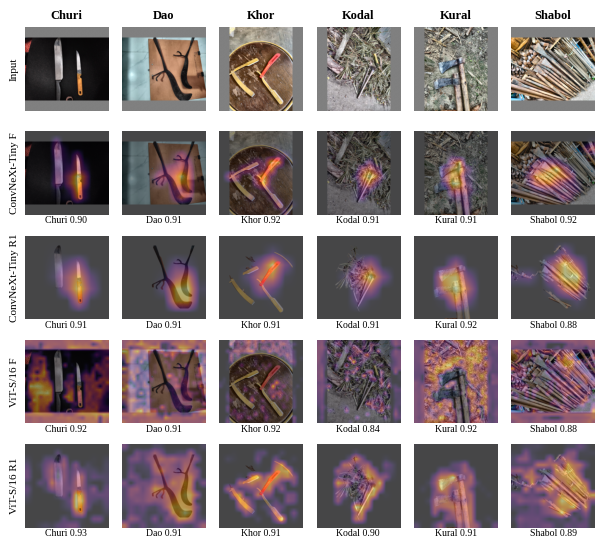

Done. Download /kaggle/working/gradcam_check.zip


In [4]:
# Figure: E3, one test image per class, ConvNeXt-Tiny vs ViT-S/16 (F pipeline + input)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "pdf.fonttype": 42})
overlay = lambda img, cam: (0.55 * img / 255 + 0.45 * plt.get_cmap("inferno")(cam)[..., :3]).clip(0, 1)
if RES["multi"] is not None:
    test = test_all[(test_all.subset == "multi") & (test_all.mask_status == "ok")]
    pick = [test[test.label == c].sample(1, random_state=SEED).iloc[0] for c in CLASSES if (test.label == c).any()]
    runs = [(m, p) for m in MODELS for p in ("F", "R1")
            if avail[(avail.scenario == "E3") & (avail.model == m) & (avail.pipeline == p)].available.any()]
    nets = {(m, p): load_run("multi", m, p) for m, p in runs}
    cams = {k: GradCAM(v[0], k[0]) for k, v in nets.items()}
    short = {"convnext_tiny": "ConvNeXt-Tiny", "vit_small_patch16_224": "ViT-S/16"}
    heads = ["Input"] + [f"{short[m]} {p}" for m, p in runs]
    fig, axes = plt.subplots(len(heads), len(pick), figsize=(1.25 * len(pick), 1.3 * len(heads)), squeeze=False,
                             gridspec_kw=dict(wspace=0.03, hspace=0.25))
    for j, r in enumerate(pick):
        tiles = [(prepare(r, nets[runs[0]][1])[0] / 255, "")]
        for k in runs:
            img, x, _ = prepare(r, nets[k][1]); cam, cls, conf = cams[k](x)
            tiles.append((overlay(img, cam), f"{CLASSES[cls]} {conf:.2f}"))
        for i, (im, t) in enumerate(tiles):
            ax = axes[i, j]; ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
            for s in ax.spines.values():
                s.set_visible(False)
            if t: ax.set_xlabel(t, fontsize=7, labelpad=1)
            if i == 0: ax.set_title(r.label, fontsize=9, fontweight="bold")
            if j == 0: ax.set_ylabel(heads[i], fontsize=8)
    for ext in ("pdf", "png"):
        fig.savefig(OUT / f"gradcam_e3_convnext_vs_vit.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

import zipfile
with zipfile.ZipFile(OUT.parent / "gradcam_check.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT.iterdir():
        z.write(f, f.name)
print("Done. Download /kaggle/working/gradcam_check.zip")